# <center> Lab 4 </center>

### Aim: To implement the Decision Tree Classification algorithm on Wine Quality dataset.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib as plt

In [2]:
data = pd.read_csv("winequality-red.csv")
data.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [3]:
data.tail()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5
1598,6.0,0.310,0.47,3.6,0.067,18.0,42.0,0.99549,3.39,0.66,11.0,6


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [5]:
data.shape

(1599, 12)

In [6]:
data.describe

<bound method NDFrame.describe of       fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0               7.4             0.700         0.00             1.9      0.076   
1               7.8             0.880         0.00             2.6      0.098   
2               7.8             0.760         0.04             2.3      0.092   
3              11.2             0.280         0.56             1.9      0.075   
4               7.4             0.700         0.00             1.9      0.076   
...             ...               ...          ...             ...        ...   
1594            6.2             0.600         0.08             2.0      0.090   
1595            5.9             0.550         0.10             2.2      0.062   
1596            6.3             0.510         0.13             2.3      0.076   
1597            5.9             0.645         0.12             2.0      0.075   
1598            6.0             0.310         0.47             3.6      0.0

In [7]:
print(data.isnull().sum())

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


In [8]:
data = data.drop_duplicates()

In [9]:
data.duplicated().sum()

0

In [10]:
data.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='object')

# 1 Univarient Analysis

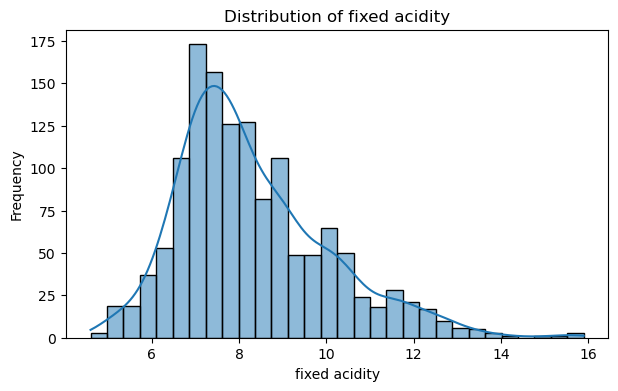

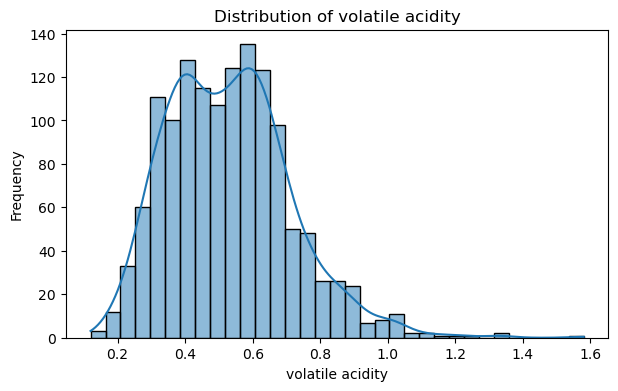

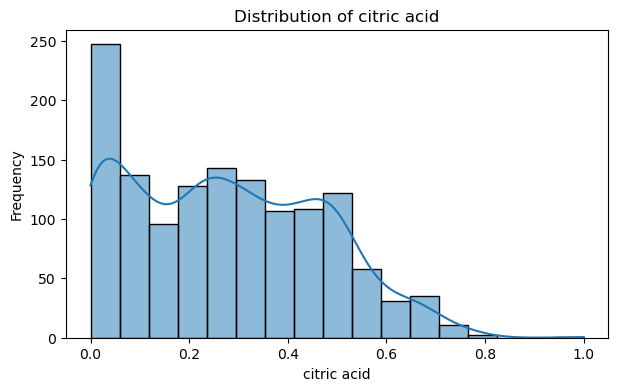

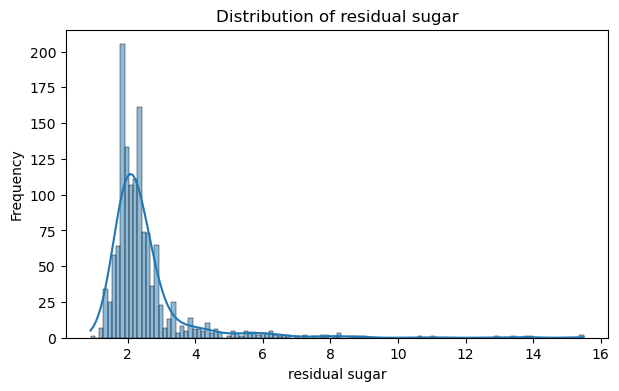

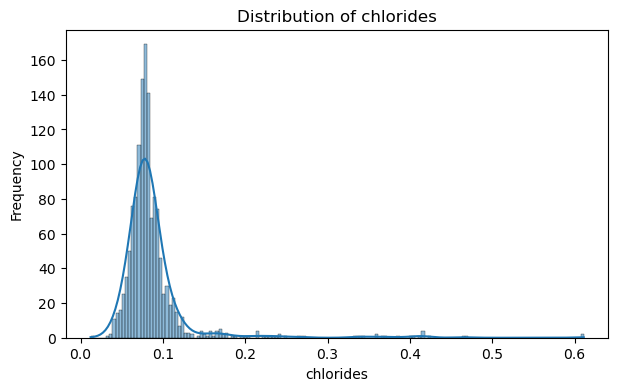

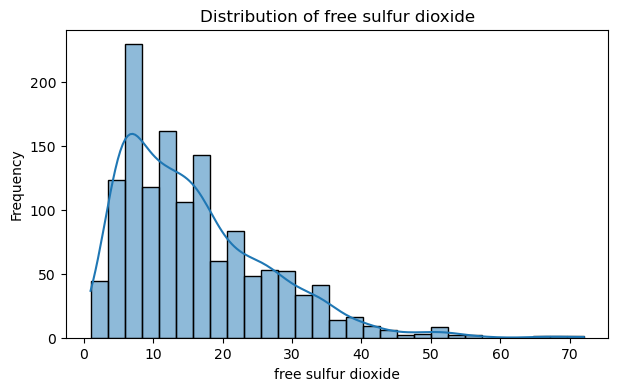

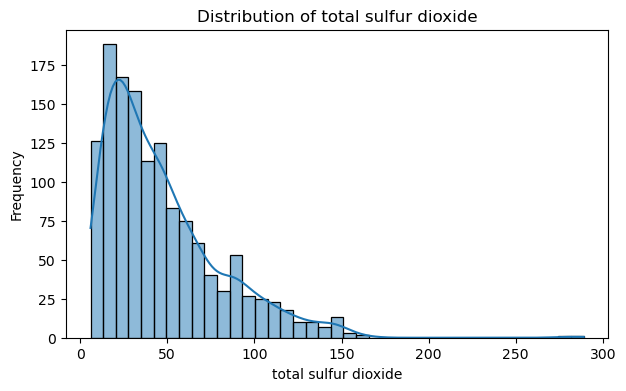

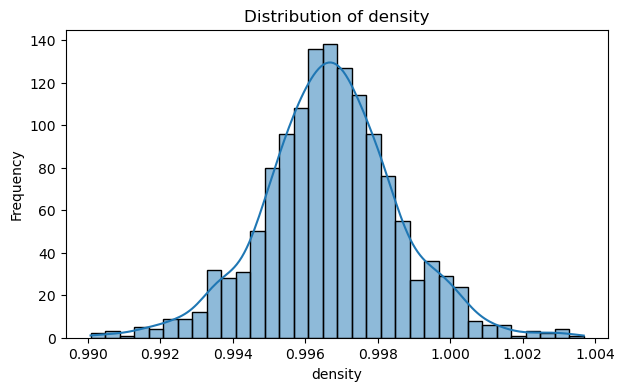

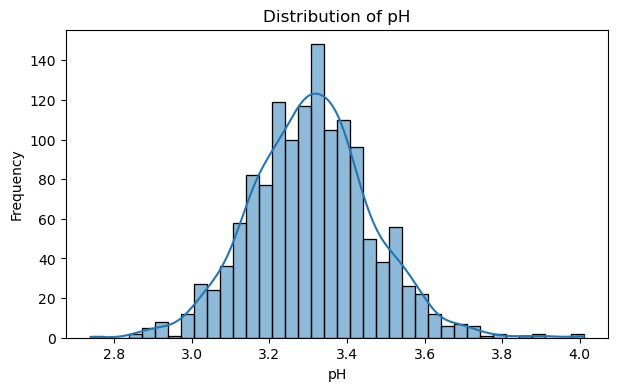

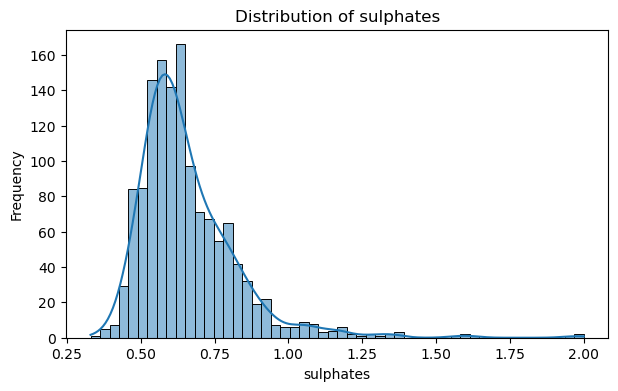

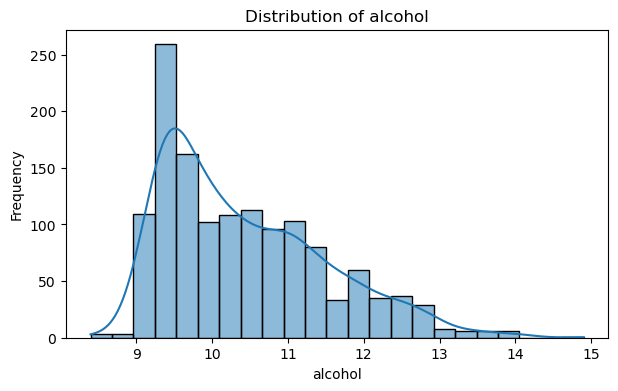

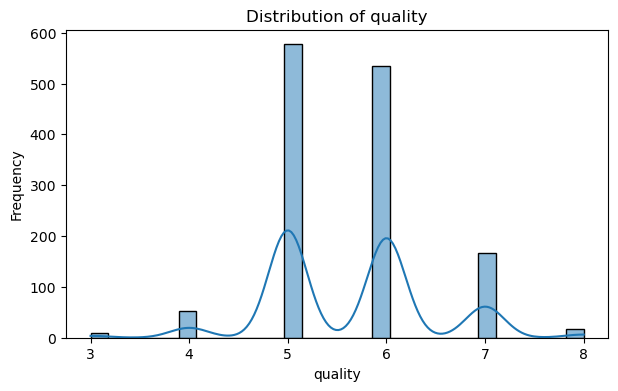

In [11]:
# Histogram + KDE
import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = data.columns

for col in numeric_cols :
    plt.figure(figsize=(7, 4))
    sns.histplot(data[col], kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

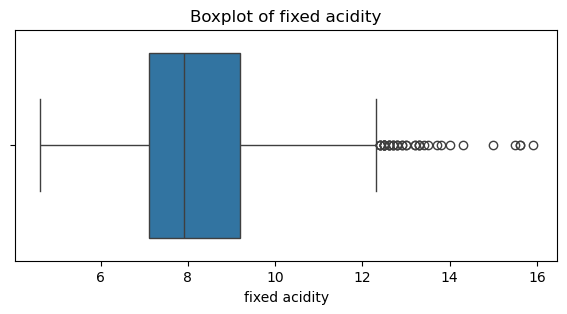

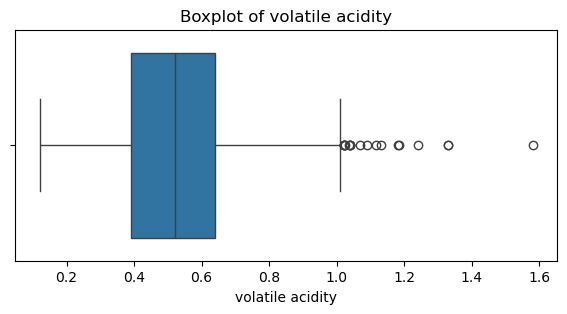

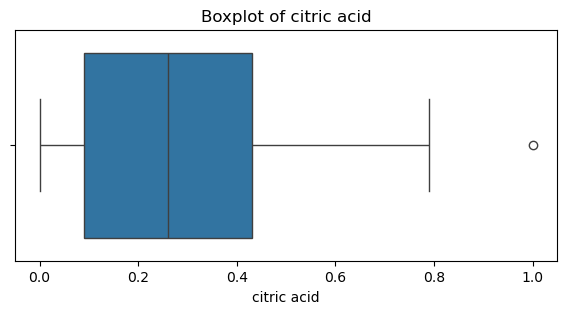

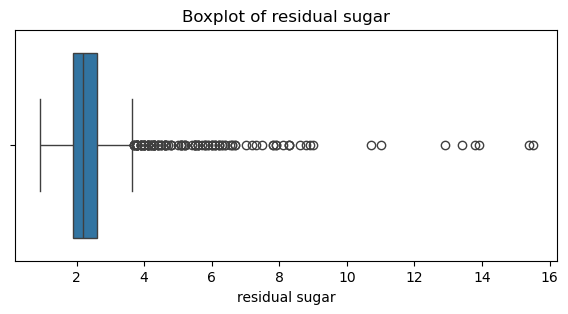

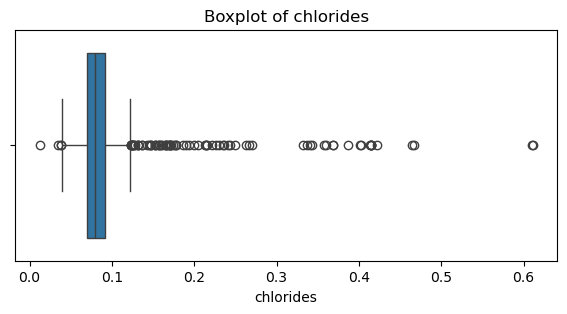

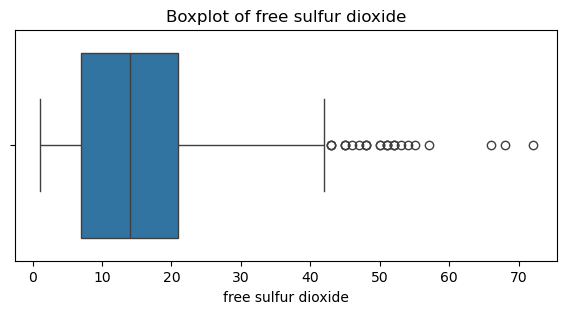

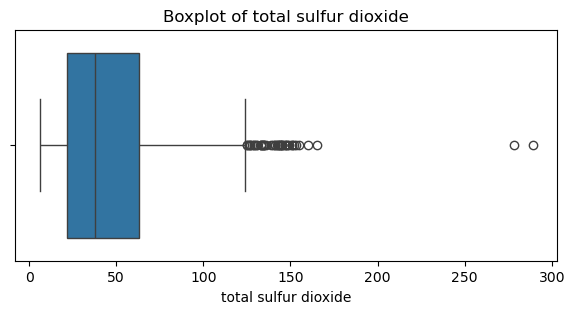

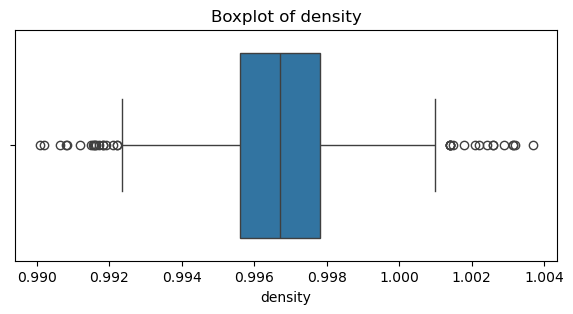

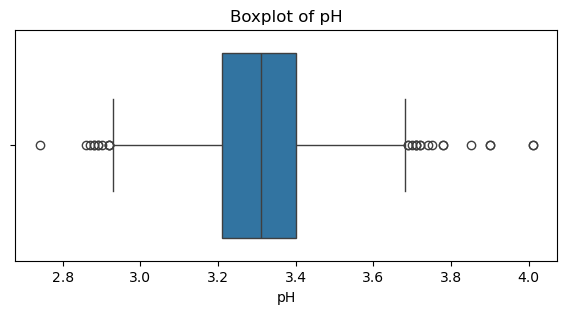

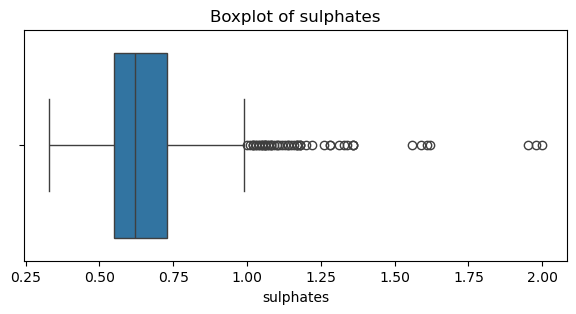

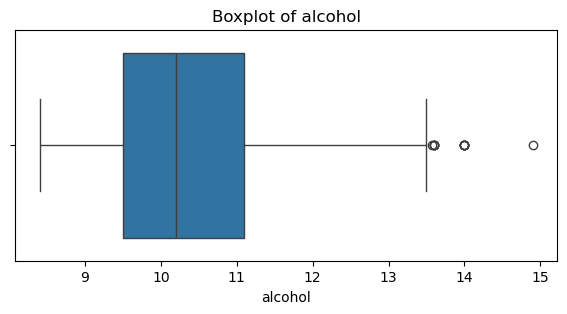

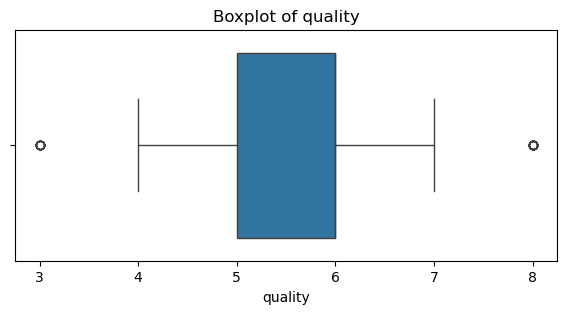

In [12]:
# Box-plot _ Outlier Detection
for col in numeric_cols :
    plt.figure(figsize=(7, 3))
    sns.boxplot(x=data[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

In [13]:
features=data.drop(columns=['quality'])
Q1=features.quantile(0.25)
Q3=features.quantile(0.75)
IQR=Q3-Q1
lower_bound=Q1-1.5*IQR
upper_bound=Q3+1.5*IQR
outlier_mask=(features<lower_bound) | (features > upper_bound)
outlier_count =outlier_mask.sum()
outlier_percentage=(outlier_count/len(features))*100
outlier_summary=pd.DataFrame({
    'Q1':Q1,
    'Q3':Q3,
    'IQR':IQR,
    "Lower_bound":lower_bound,
    "Upper_bound":upper_bound,
    "Outlier count":outlier_count,
    "Outlier %":outlier_percentage
})
outlier_summary.round(3)

,Q1,Q3,IQR,Lower_bound,Upper_bound,Outlier count,Outlier %
fixed acidity,7.100,9.200,2.100,3.950,12.350,41,3.017
volatile acidity,0.390,0.640,0.250,0.015,1.015,19,1.398
citric acid,0.090,0.430,0.340,-0.420,0.940,1,0.074
residual sugar,1.900,2.600,0.700,0.850,3.650,126,9.272
chlorides,0.070,0.091,0.021,0.039,0.122,87,6.402
free sulfur dioxide,7.000,21.000,14.000,-14.000,42.000,26,1.913
total sulfur dioxide,22.000,63.000,41.000,-39.500,124.500,45,3.311
density,0.996,0.998,0.002,0.992,1.001,35,2.575
pH,3.210,3.400,0.190,2.925,3.685,28,2.060
sulphates,0.550,0.730,0.180,0.280,1.000,55,4.047


In [14]:

print("Outlier in each feature:\n")

for column in features.columns:
    print(f"{column:25s}: {outlier_count[column]}")

Outlier in each feature:

fixed acidity            : 41
volatile acidity         : 19
citric acid              : 1
residual sugar           : 126
chlorides                : 87
free sulfur dioxide      : 26
total sulfur dioxide     : 45
density                  : 35
pH                       : 28
sulphates                : 55
alcohol                  : 12


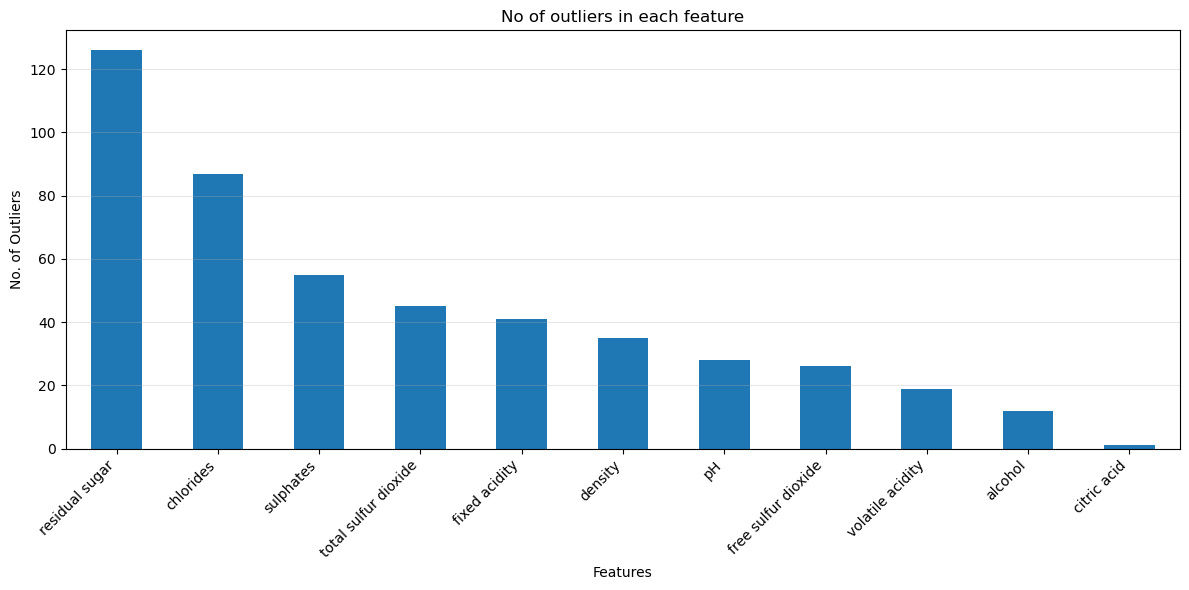

In [15]:
plt.figure(figsize=(12,6))
outlier_count.sort_values(ascending=False).plot(
    kind='bar'
)
plt.title("No of outliers in each feature")
plt.xlabel("Features")
plt.ylabel("No. of Outliers")
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

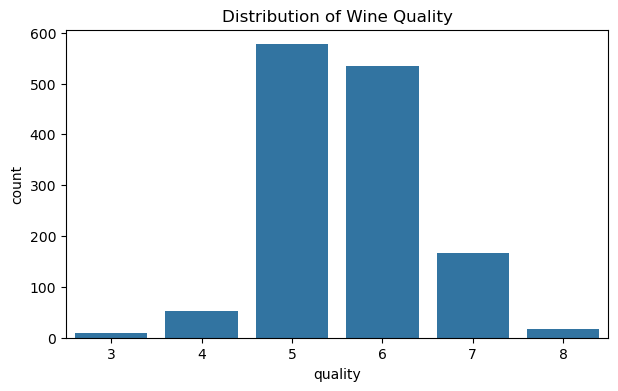

In [16]:
plt.figure(figsize=(7, 4))
sns.countplot(x='quality', data = data)
plt.title('Distribution of Wine Quality')
plt.show()

In [17]:
data['quality'].value_counts().sort_index()

quality
3     10
4     53
5    577
6    535
7    167
8     17
Name: count, dtype: int64

# Bivariate Analysis

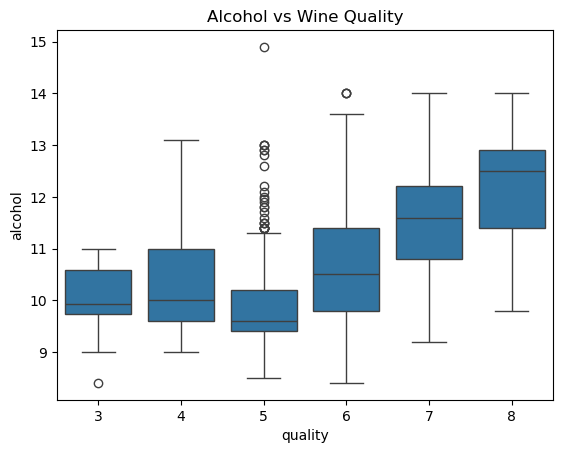

In [18]:
# Alcohol vs Quality
sns.boxplot(x='quality',y='alcohol',data=data)
plt.title('Alcohol vs Wine Quality')
plt.show()

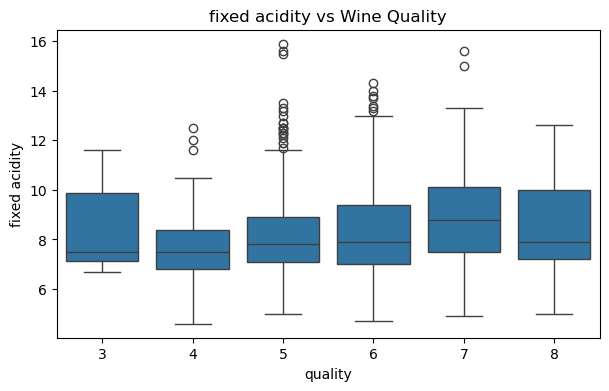

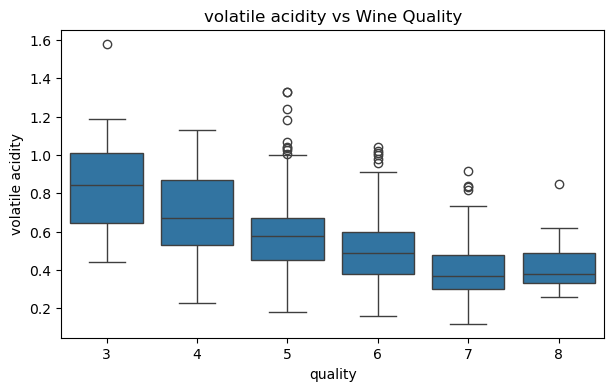

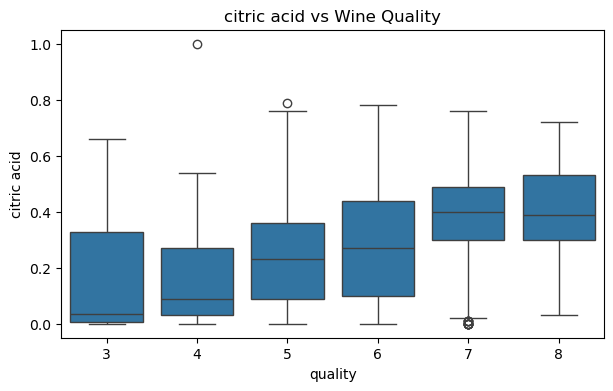

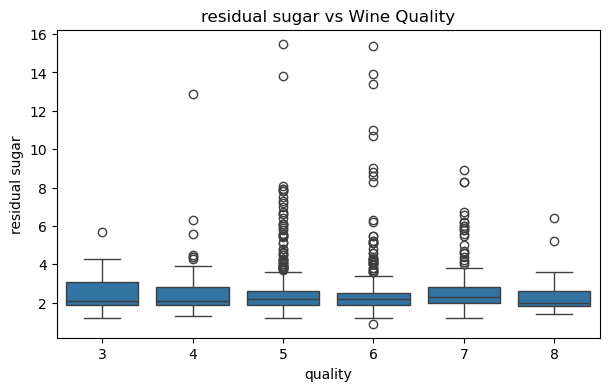

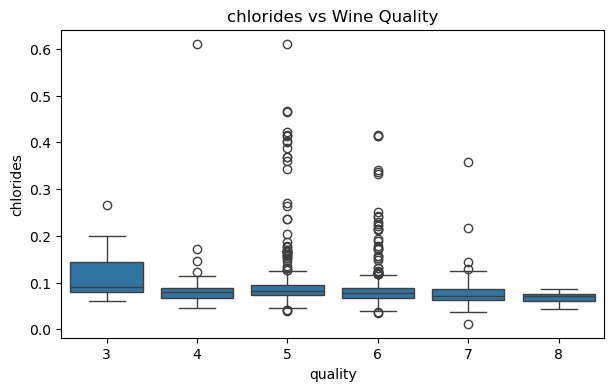

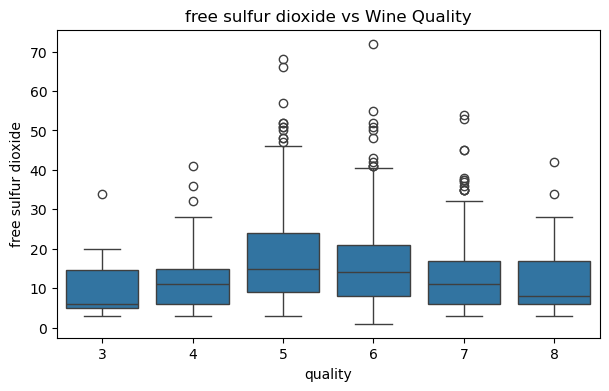

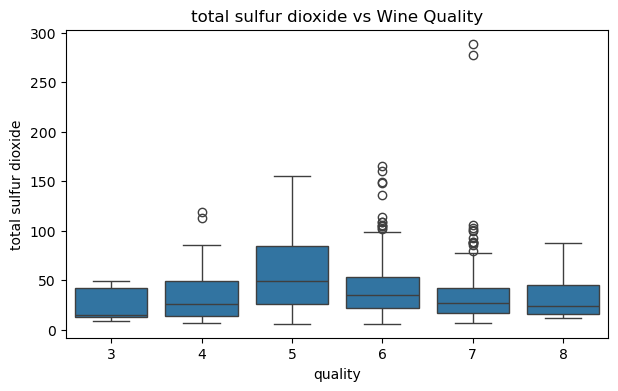

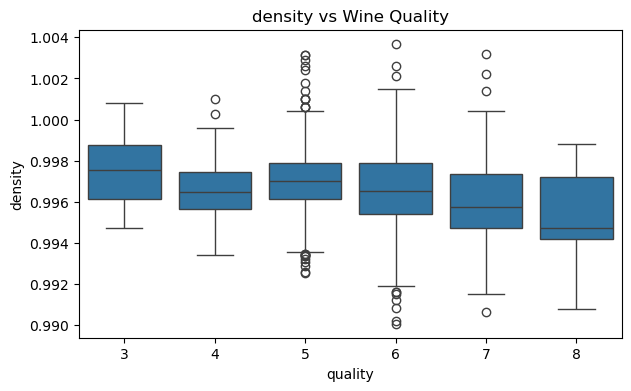

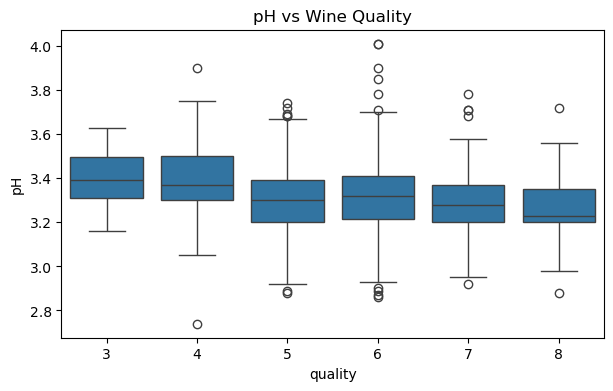

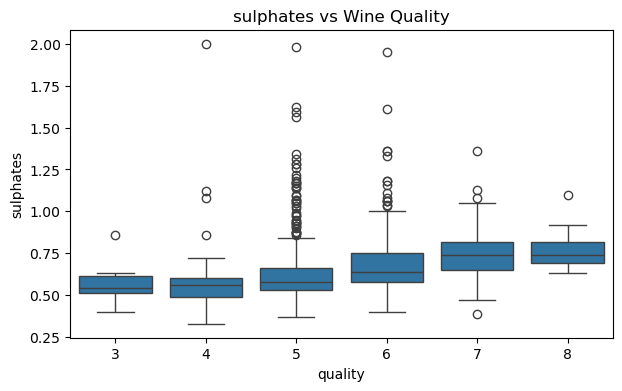

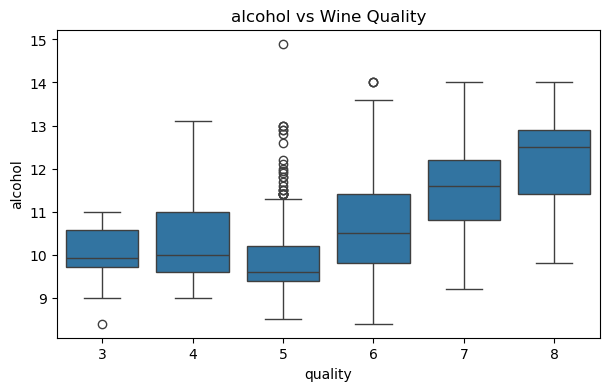

In [19]:
features = ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol']

for col in features :
    plt.figure(figsize=(7, 4))
    sns.boxplot(x='quality', y=col, data = data)
    plt.title(f"{col} vs Wine Quality")
    plt.show()

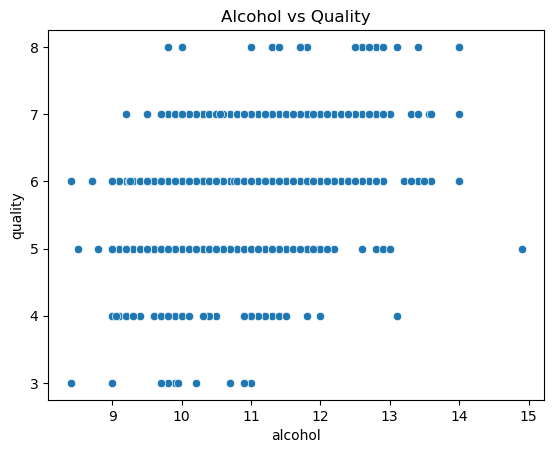

In [20]:
sns.scatterplot(x='alcohol',y='quality',data=data)
plt.title('Alcohol vs Quality')
plt.show()

# Mutivariate Anaylsis

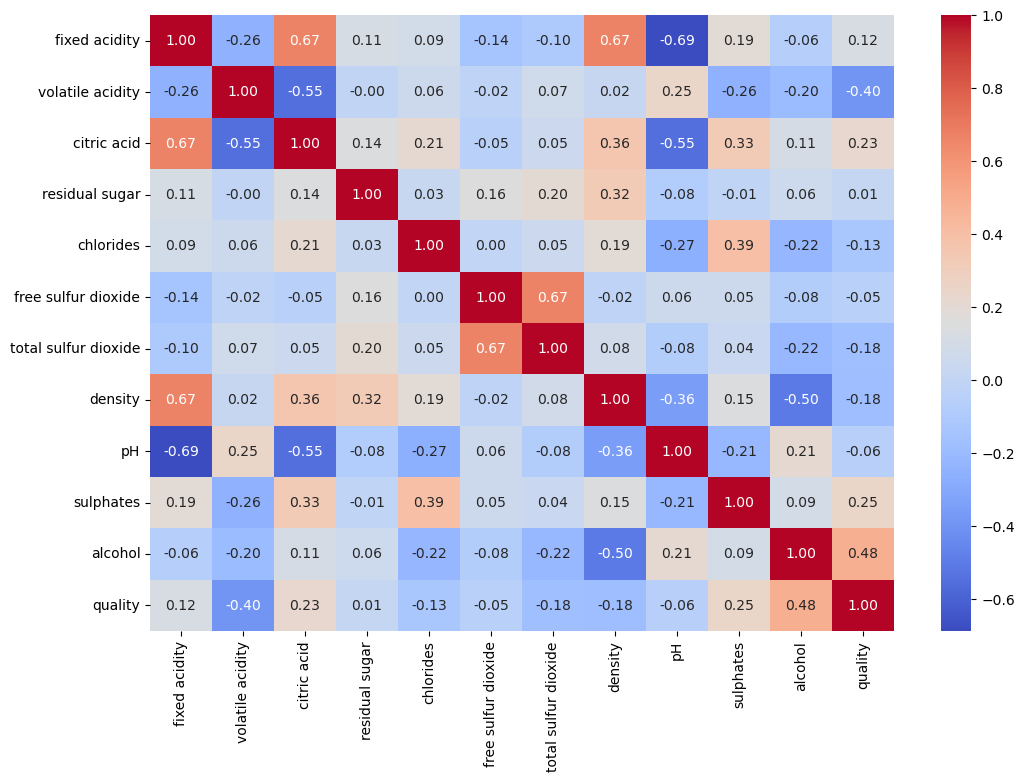

In [21]:
plt.figure(figsize=(12,8))
corr=data.corr()
sns.heatmap(corr,annot=True, cmap='coolwarm',fmt='.2f')
plt.show()

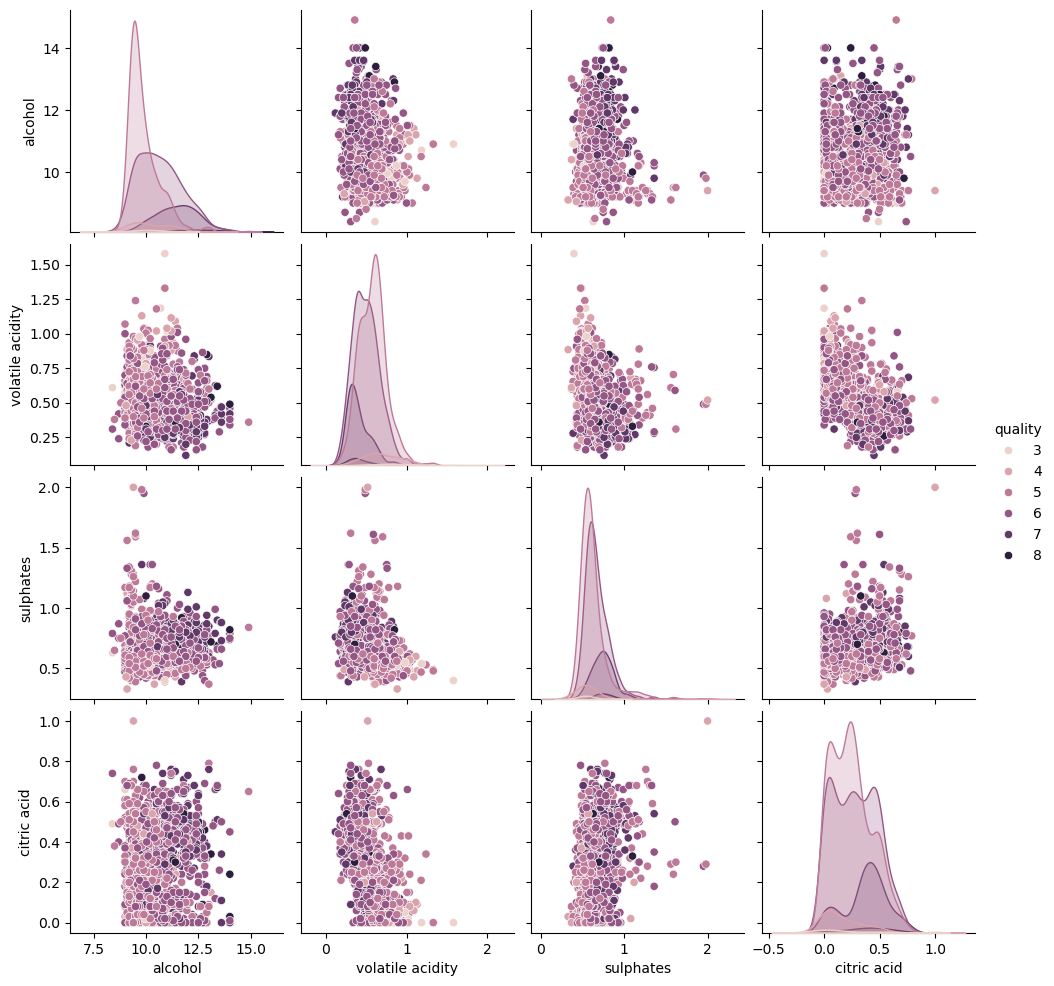

In [22]:
selected=['alcohol','volatile acidity', 'sulphates','citric acid','quality']
sns.pairplot(data[selected],hue='quality')
plt.show()

In [23]:
# Explicitly apply to all rows using .loc
data.loc[:, 'quality_group'] = pd.cut(
    data['quality'], 
    bins=[0, 5, 6, 10], 
    labels=['low', 'medium', 'high'], 
    include_lowest=True
)


C:\Users\HP\AppData\Local\Temp\ipykernel_11240\952505088.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data.loc[:, 'quality_group'] = pd.cut(


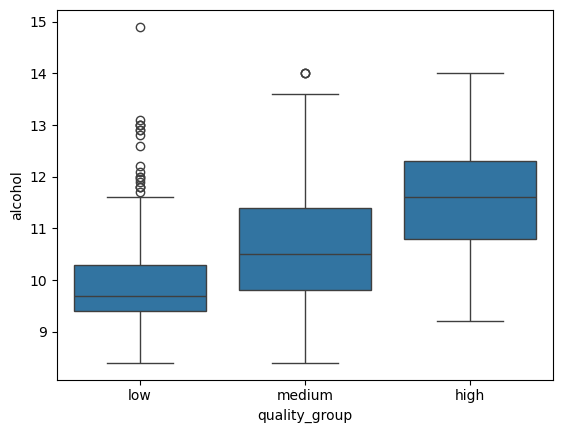

In [24]:
sns.boxplot(
    x='quality_group',
    y='alcohol',
    data=data
)
plt.show()

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score,recall_score,f1_score,classification_report,confusion_matrix,ConfusionMatrixDisplay)

In [26]:
X=data.drop('quality',axis=1)
y=data['quality']

In [27]:
print("X shape",X.shape)

X shape (1359, 12)


In [28]:
print("Y shape",y.shape)

Y shape (1359,)


In [29]:
print(y.value_counts().sort_index())

quality
3     10
4     53
5    577
6    535
7    167
8     17
Name: count, dtype: int64


In [30]:
X_train, X_test, y_train, y_test=train_test_split(X,y,test_size=0.20,
                                                 random_state=42,
                                                 stratify=y)

In [31]:
criterian='entropy'

In [32]:
dt_model=DecisionTreeClassifier(
    criterion='entropy',
    random_state=42
)

In [33]:
data.loc[:, 'quality_group'] = pd.cut(
    data['quality'], 
    bins=[0, 5, 6, 10], 
    labels=['low', 'medium', 'high'], 
    include_lowest=True
)


In [34]:
print(X.columns)

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality_group'],
      dtype='object')


In [35]:
print(X.select_dtypes(exclude='number').columns)

Index(['quality_group'], dtype='object')


In [36]:
y=data['quality']

In [37]:
X=data.drop(columns=['quality','quality_group'],errors='ignore')

In [38]:
print(X.columns)
print(X.dtypes)

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol'],
      dtype='object')
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
dtype: object


In [39]:
X_train, X_test, y_train, y_test=train_test_split(X,y,test_size=0.20,
                                                 random_state=42,
                                                 stratify=y)

In [40]:
from sklearn.tree import DecisionTreeClassifier
dt_model=DecisionTreeClassifier(criterion='entropy',random_state=42)

In [41]:
dt_model.fit(X_train, y_train)

DecisionTreeClassifier(criterion='entropy', random_state=42)

In [42]:
dt_model.fit(X_train, y_train)

DecisionTreeClassifier(criterion='entropy', random_state=42)

In [43]:
y_train_pred=dt_model.predict(X_train)
y_test_pred=dt_model.predict(X_test)

In [44]:
train_accuracy=accuracy_score(y_train, y_train_pred)
print(train_accuracy)

1.0


In [45]:
test_accuracy=accuracy_score(y_test,y_test_pred)
print(test_accuracy)

0.4963235294117647


In [46]:
print("Precision:", precision_score(y_test, y_test_pred, average='weighted'))
print("Recall:", recall_score(y_test,y_test_pred, average='weighted'))
print("F1 Score:", f1_score(y_test, y_test_pred, average='weighted'))


Precision: 0.49434982217769985
Recall: 0.4963235294117647
F1 Score: 0.4951045941835992


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [47]:
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.64      0.62      0.63       116
           6       0.47      0.50      0.48       107
           7       0.29      0.30      0.30        33
           8       0.00      0.00      0.00         3

    accuracy                           0.50       272
   macro avg       0.23      0.24      0.24       272
weighted avg       0.49      0.50      0.50       272



C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


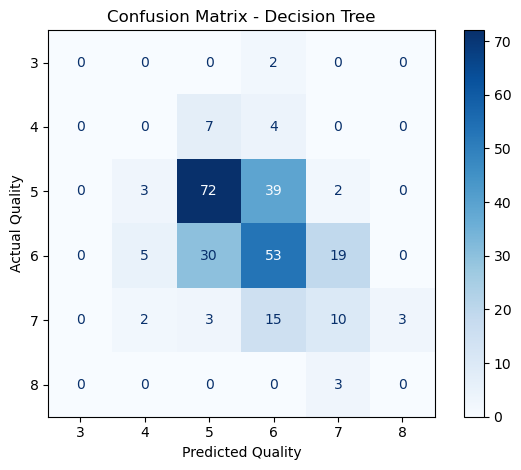

In [48]:
#Confusion matrix
labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_test_pred, labels=labels)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)
disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix - Decision Tree')
plt.xlabel('Predicted Quality')
plt.ylabel('Actual Quality')
plt.tight_layout()
plt.show()

In [49]:
print("Tree depth:",dt_model.get_depth())
print("Number of leaves:",dt_model.get_n_leaves())

Tree depth: 18
Number of leaves: 299


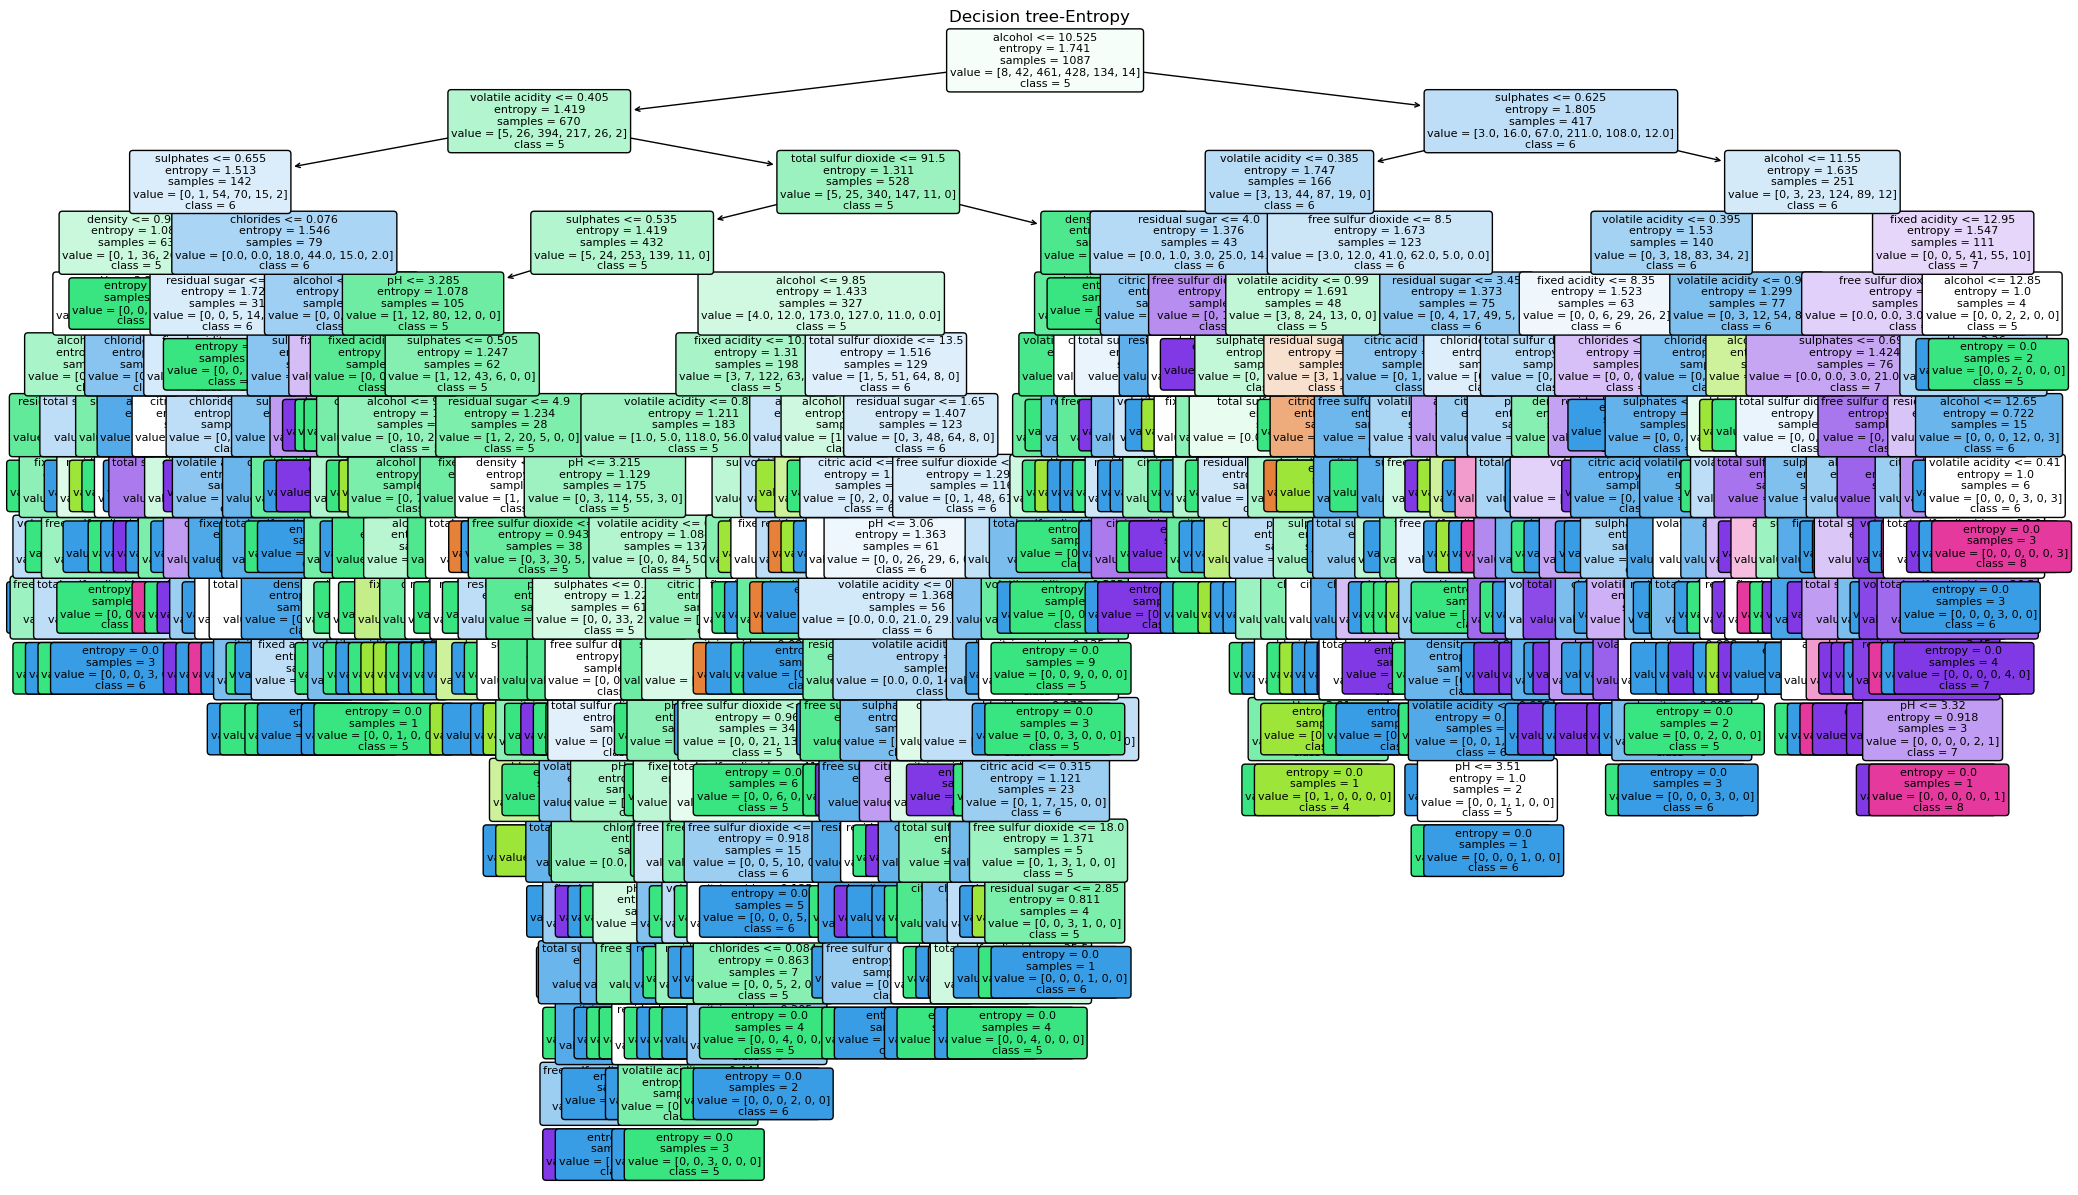

In [50]:
plt.figure(figsize=(25,15))
plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=[str(c) for c in sorted(y.unique())],
    filled=True,
    rounded=True,
    fontsize=8,
)
plt.title("Decision tree-Entropy")
plt.show()

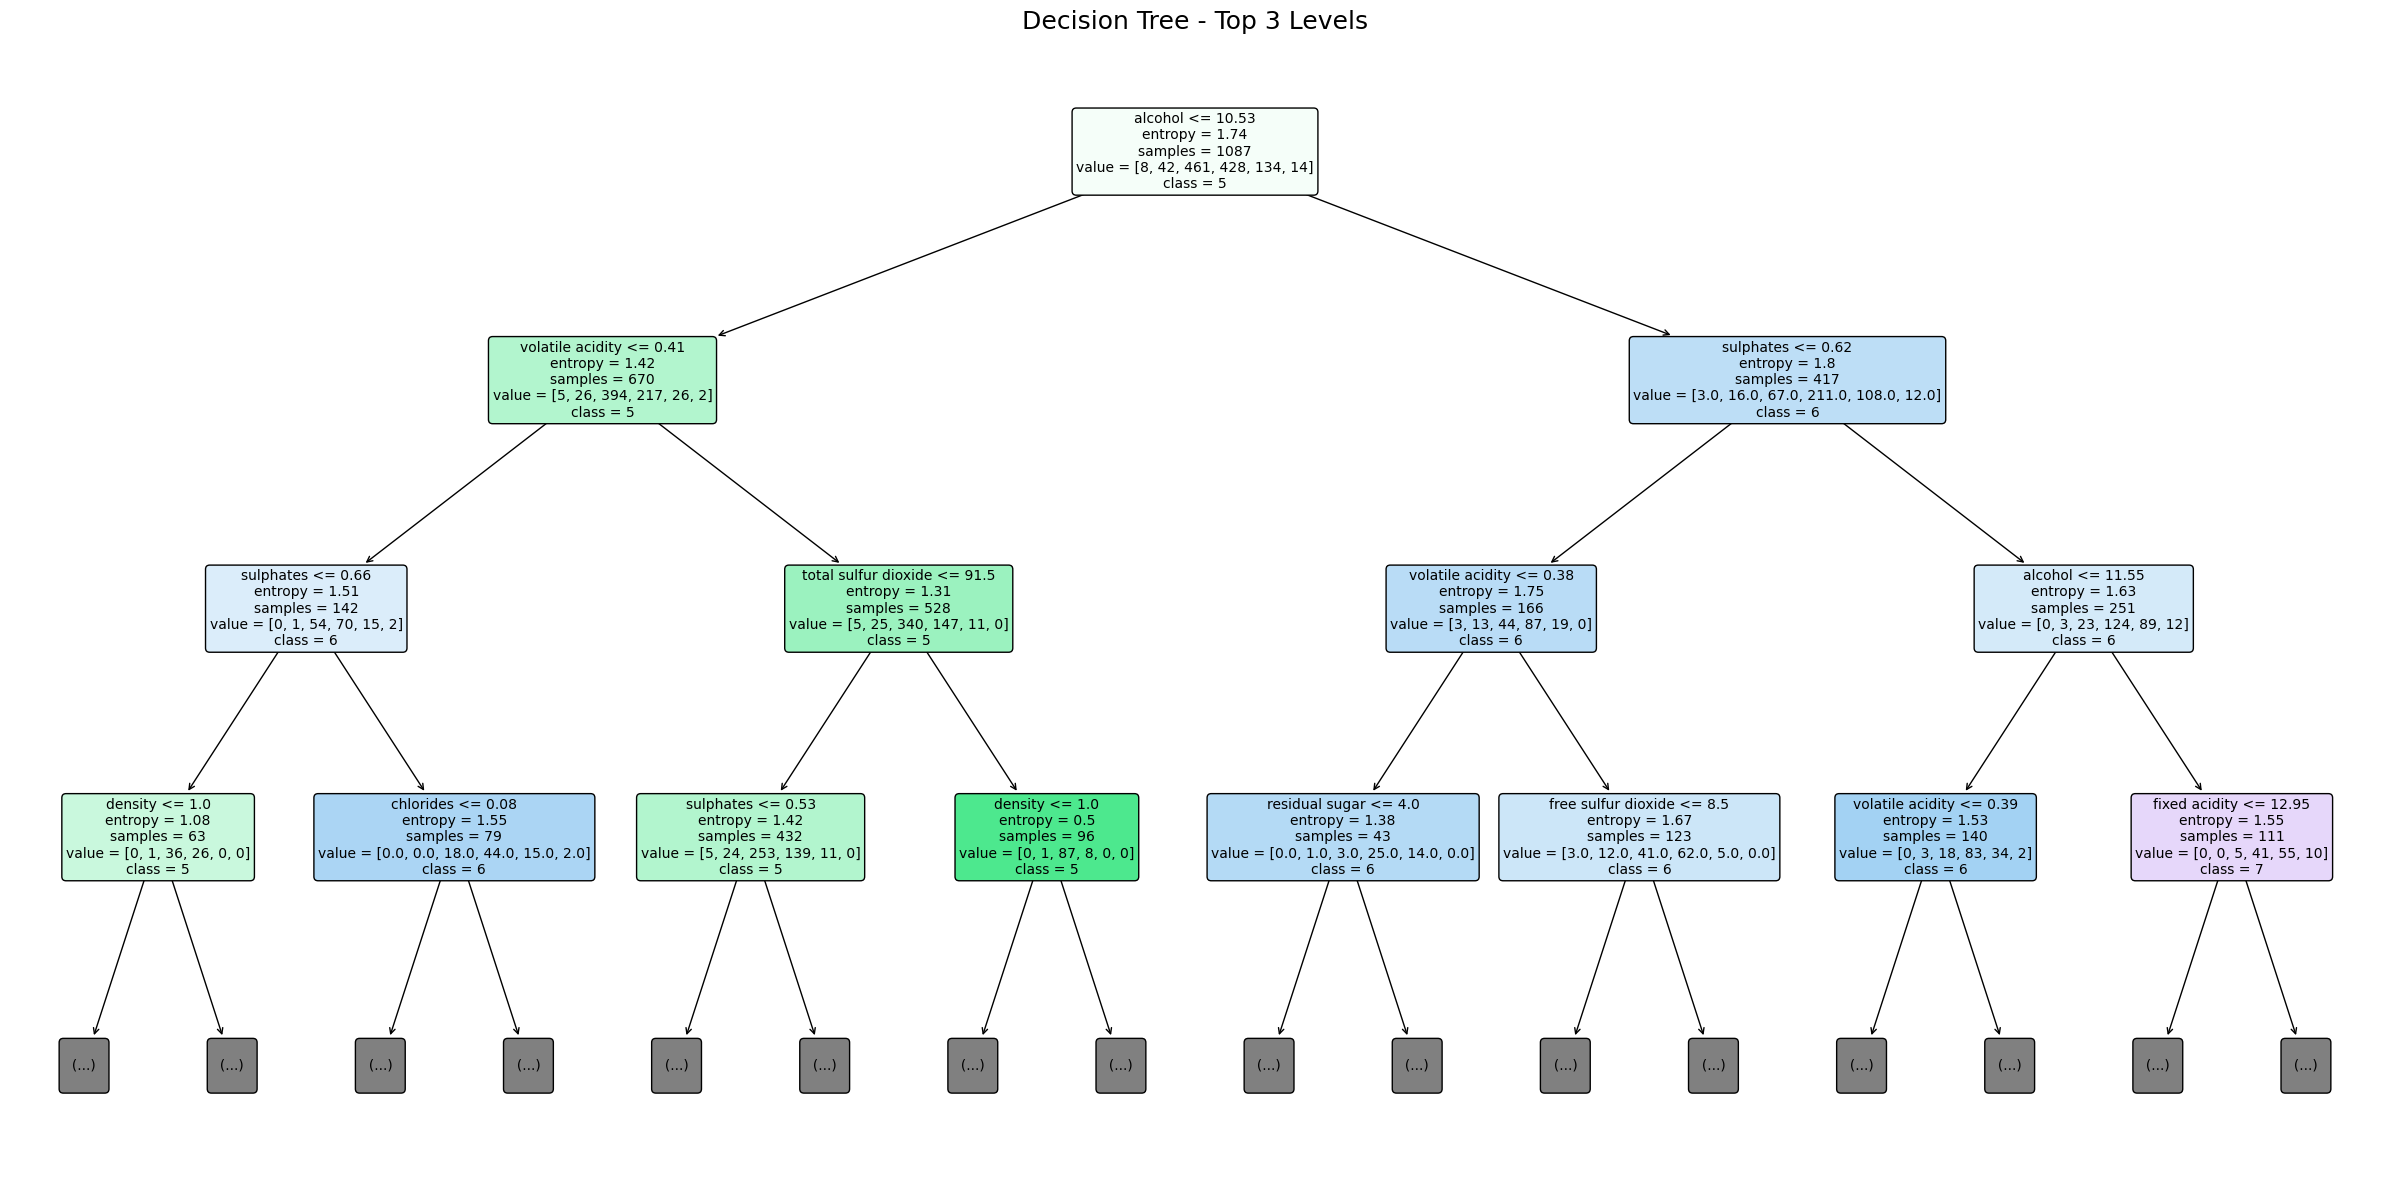

In [51]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(24, 12))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=[str(c) for c in sorted(y.unique())],
    filled=True,
    rounded=True,
    impurity=True,
    precision=2,
    fontsize=10,
    max_depth=3
)

plt.title("Decision Tree - Top 3 Levels", fontsize=18)
plt.tight_layout()
plt.show()

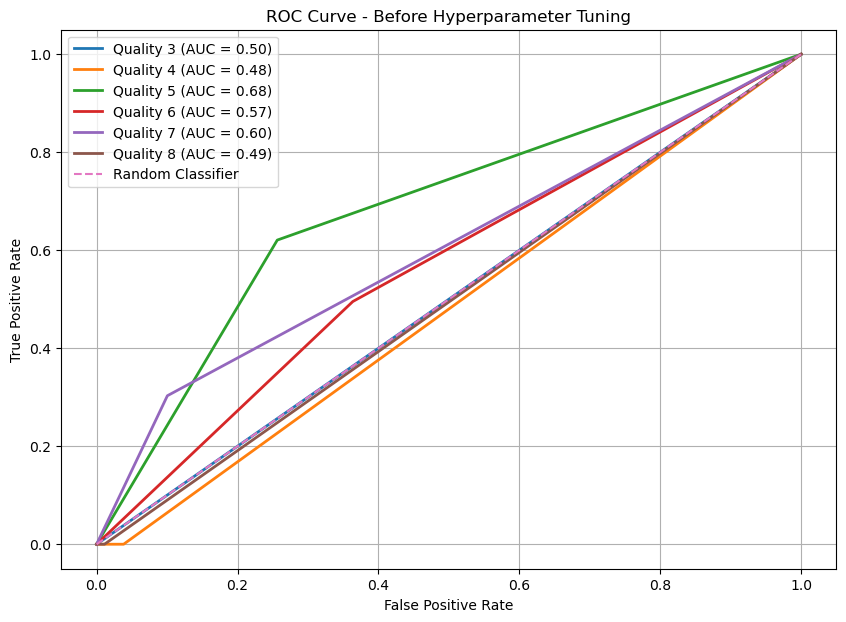

Overall ROC-AUC Before Hyperparameter Tuning: 0.5541


In [52]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score
import matplotlib.pyplot as plt
import numpy as np
classes = sorted(y_test.unique())
y_test_bin = label_binarize(y_test, classes=classes)
y_score = dt_model.predict_proba(X_test)
plt.figure(figsize=(10, 7))

for i, class_label in enumerate(classes):
    fpr, tpr, thresholds = roc_curve(y_test_bin[:, i],y_score[:, i])
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr,tpr,linewidth=2,
        label=f'Quality {class_label} (AUC = {roc_auc:.2f})'
    )

plt.plot([0, 1],[0, 1],linestyle='--',label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Before Hyperparameter Tuning')
plt.legend()
plt.grid()
plt.show()

overall_auc_before = roc_auc_score(
    y_test,
    y_score,
    multi_class='ovr',
    average='macro'
)

print(f"Overall ROC-AUC Before Hyperparameter Tuning: {overall_auc_before:.4f}")

In [53]:
# Hyperparameter Tuning
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
import warnings

warnings.filterwarnings('ignore')

param_grid = {
    'criterion': ['entropy'],
    'max_depth': [3, 5, 7, 10, None],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 4, 8],
    'max_features': [None, 'sqrt', 'log2'],
    'ccp_alpha': [0, 0.001, 0.005, 0.01]
}

grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best Parameters:")
print(grid.best_params_)

print("Best CV Score:")
print(grid.best_score_)

best_tree = grid.best_estimator_

Best Parameters:
{'ccp_alpha': 0.01, 'criterion': 'entropy', 'max_depth': 7, 'max_features': None, 'min_samples_leaf': 8, 'min_samples_split': 20}
Best CV Score:
0.5814399864710607


In [54]:
y_pred=best_tree.predict(X_test)
print(classification_report(y_test,y_pred))
print("Accuracy=",accuracy_score(y_test,y_pred))

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.63      0.69      0.66       116
           6       0.53      0.54      0.54       107
           7       0.47      0.52      0.49        33
           8       0.00      0.00      0.00         3

    accuracy                           0.57       272
   macro avg       0.27      0.29      0.28       272
weighted avg       0.54      0.57      0.55       272

Accuracy= 0.5698529411764706


In [55]:
train_accuracy=best_tree.score(X_train, y_train)
test_accuracy=best_tree.score(X_test, y_test)
print("Training accuracy:",train_accuracy)
print("Testing accuracy:",test_accuracy)

Training accuracy: 0.6209751609935602
Testing accuracy: 0.5698529411764706


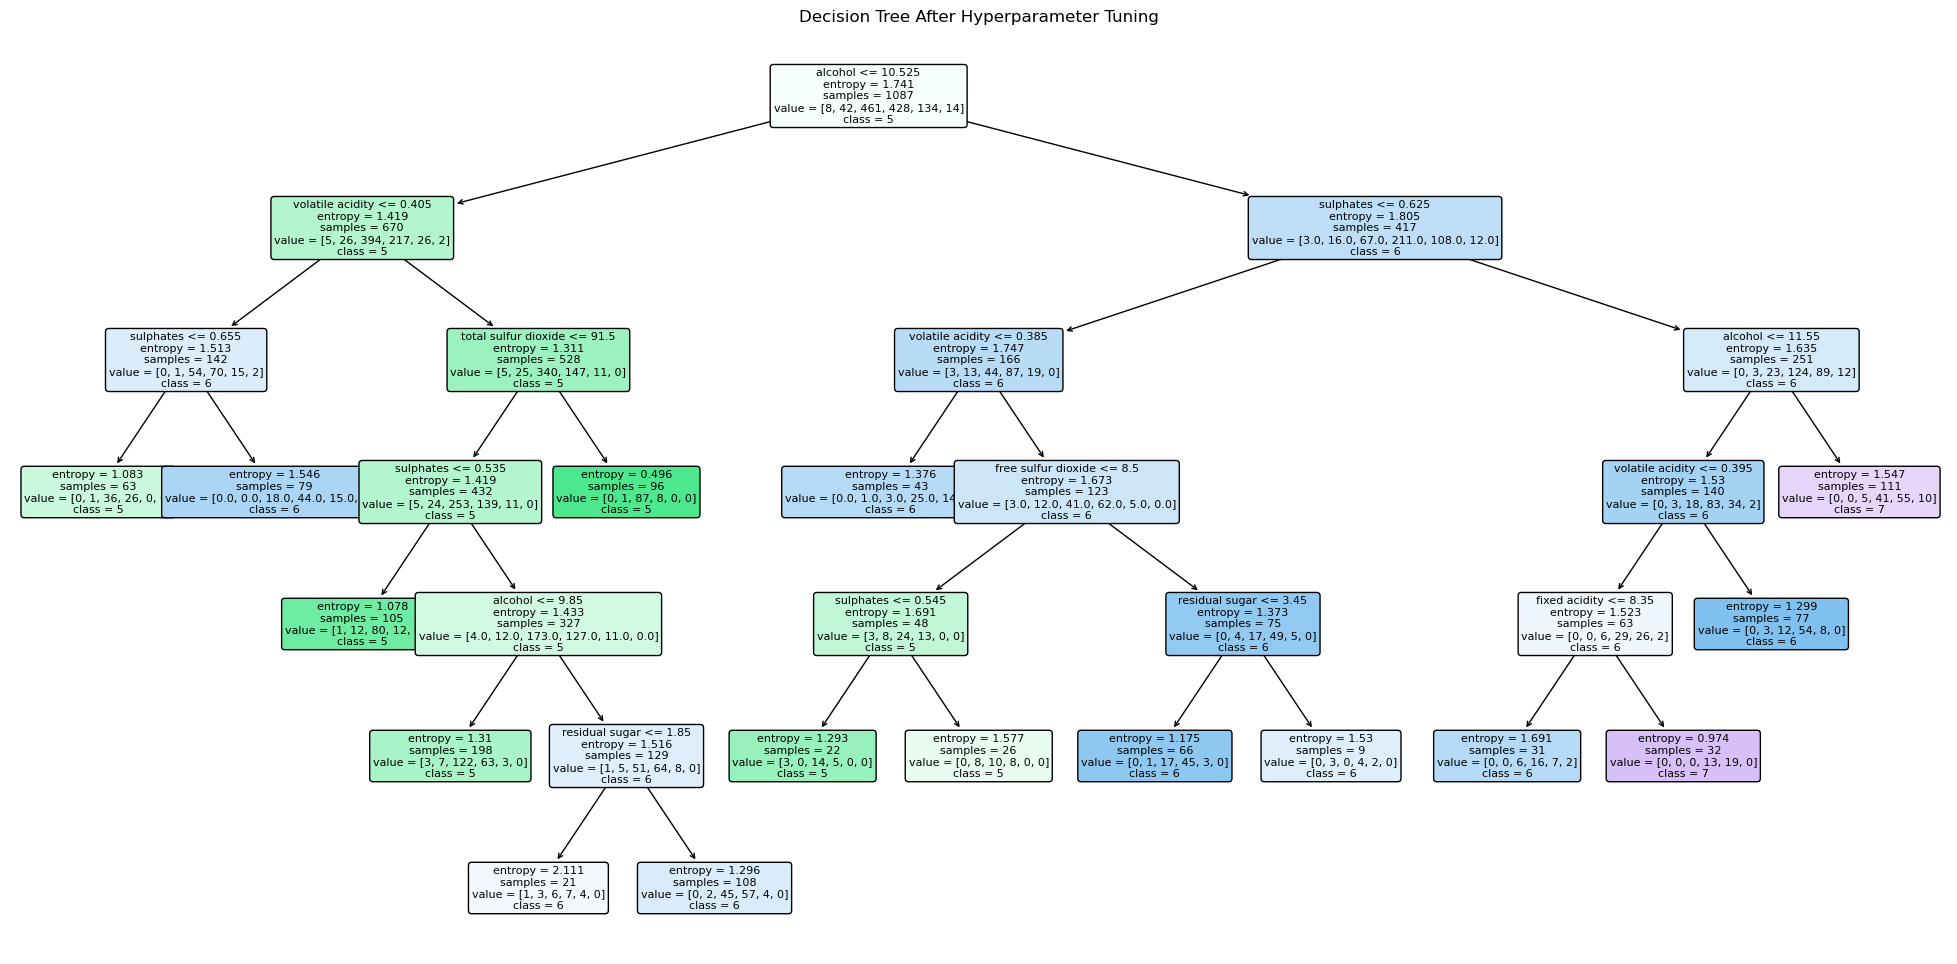

In [62]:
from sklearn.tree import plot_tree
plt.figure(figsize=(25,12))
plot_tree(
    best_tree,
    feature_names=X.columns,
    class_names=[str(c) for c in best_tree.classes_],
    filled=True,
    rounded=True,
   fontsize=8
)
plt.title("Decision Tree After Hyperparameter Tuning")
plt.show()

# Cross Validation

In [64]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    best_tree,
    X_train,
    y_train,
    cv=10,
    scoring="accuracy"
)

print("Cross-Validation Scores:", cv_scores)
print("Mean CV Accuracy:", cv_scores.mean())
print("Standard Deviation:", cv_scores.std())

Cross-Validation Scores: [0.4587156  0.53211009 0.59633028 0.55963303 0.57798165 0.48623853
 0.58715596 0.62962963 0.55555556 0.60185185]
Mean CV Accuracy: 0.5585202174651716
Standard Deviation: 0.05045360205123231


# Learning Curve

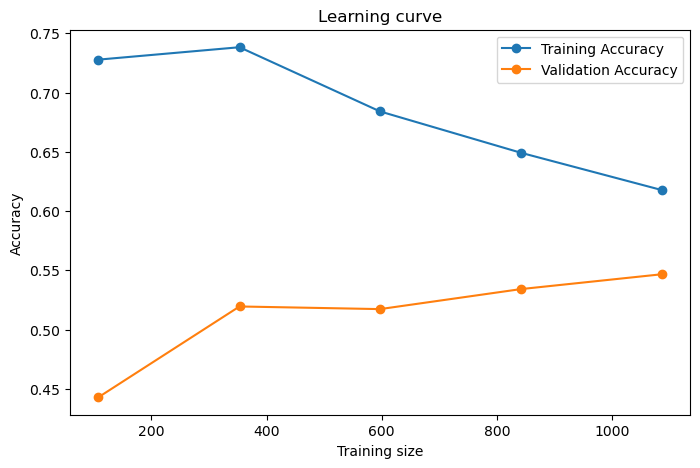

In [66]:
from sklearn.model_selection import learning_curve
train_sizes, train_scores, test_scores=learning_curve(best_tree,X,y,cv=5,scoring='accuracy')
plt.figure(figsize=(8,5))
plt.plot(train_sizes,train_scores.mean(axis=1),marker='o',label='Training Accuracy')
plt.plot(train_sizes,test_scores.mean(axis=1),marker='o',label='Validation Accuracy')
plt.xlabel("Training size")
plt.ylabel("Accuracy")
plt.title("Learning curve")
plt.legend()
plt.show()

In [67]:
new_wine=pd.DataFrame([{
    'fixed acidity':7.0,
    'volatile acidity':0.50,
    'citric acid':0.20,
    'residual sugar':2.0,
    'chlorides':0.070,
    'free sulfur dioxide':15.0,
    'total sulfur dioxide':40.0,
    'density':0.995,
    'pH':3.30,
    'sulphates':0.60,
    'alcohol':10.0
}])
prediction=best_tree.predict(new_wine)
print("Predicted wine quality:",prediction[0])

Predicted wine quality: 6


In [70]:
probability=best_tree.predict_proba(new_wine)
print("Predicted quality:",prediction[0])
print("Probability:",probability)

Predicted quality: 6
Probability: [[0.         0.01851852 0.41666667 0.52777778 0.03703704 0.        ]]
